In [1]:
from io import StringIO
import pandas as pd

data = """transaction_id,date,channel,amount_ghs,status,agent_area
T001,2026-10-01,Mobile Money,250,Successful,Madina
T002,2026-10-01,Bank Transfer,1200,Successful,East Legon
T003,2026-10-01,Mobile Money,75,FAILED,Madina
T004,2026-10-02,Card,450,Successful,Osu
T005,2026-10-02,Mobile Money,0,Successful,Madina
T006,2026-10-02,Bank Transfer,800,Pending,East Legon
T007,2026-10-03,Card,320,Successful,Osu
T008,2026-10-03,Mobile Money,150,successful,Madina
T008,2026-10-03,Mobile Money,150,successful,Madina
T009,2026-10-03,Bank Transfer,,Successful,East Legon
T010,2026-10-04,Mobile Money,90,Failed,Madina
T011,2026-10-04,Card,600,Successful,Osu
T012,2026-10-04,Bank Transfer,500,Successful,East Legon
T013,2026-10-05,Mobile Money,200,Successful,Madina
T014,2026-10-05,Card,150,Successful,Osu
T015,2026-10-05,Mobile Money,300, successful ,Madina
"""

df = pd.read_csv(StringIO(data))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (16, 6)


,transaction_id,date,channel,amount_ghs,status,agent_area
0,T001,2026-10-01,Mobile Money,250.0,Successful,Madina
1,T002,2026-10-01,Bank Transfer,1200.0,Successful,East Legon
2,T003,2026-10-01,Mobile Money,75.0,FAILED,Madina
3,T004,2026-10-02,Card,450.0,Successful,Osu
4,T005,2026-10-02,Mobile Money,0.0,Successful,Madina


In [2]:
df.head(16)

,transaction_id,date,channel,amount_ghs,status,agent_area
0,T001,2026-10-01,Mobile Money,250.0,Successful,Madina
1,T002,2026-10-01,Bank Transfer,1200.0,Successful,East Legon
2,T003,2026-10-01,Mobile Money,75.0,FAILED,Madina
3,T004,2026-10-02,Card,450.0,Successful,Osu
4,T005,2026-10-02,Mobile Money,0.0,Successful,Madina
5,T006,2026-10-02,Bank Transfer,800.0,Pending,East Legon
6,T007,2026-10-03,Card,320.0,Successful,Osu
7,T008,2026-10-03,Mobile Money,150.0,successful,Madina
8,T008,2026-10-03,Mobile Money,150.0,successful,Madina
9,T009,2026-10-03,Bank Transfer,NaN,Successful,East Legon


In [3]:
df.shape

(16, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  16 non-null     object 
 1   date            16 non-null     object 
 2   channel         16 non-null     object 
 3   amount_ghs      15 non-null     float64
 4   status          16 non-null     object 
 5   agent_area      16 non-null     object 
dtypes: float64(1), object(5)
memory usage: 900.0+ bytes


In [5]:
df.isna().sum()

,0
transaction_id,0
date,0
channel,0
amount_ghs,1
status,0
agent_area,0


In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
df[df.duplicated(subset='transaction_id', keep=False)]

,transaction_id,date,channel,amount_ghs,status,agent_area
7,T008,2026-10-03,Mobile Money,150.0,successful,Madina
8,T008,2026-10-03,Mobile Money,150.0,successful,Madina


In [8]:
df_clean = df.drop_duplicates().copy()
print(df_clean.shape)

(15, 6)


In [9]:
df_clean['status'] = (df_clean['status'].str.strip().str.title())
print(df_clean['status'])

0     Successful
1     Successful
2         Failed
3     Successful
4     Successful
5        Pending
6     Successful
7     Successful
9     Successful
10        Failed
11    Successful
12    Successful
13    Successful
14    Successful
15    Successful
Name: status, dtype: object


In [10]:
df_clean['amount_ghs'] = pd.to_numeric(df_clean['amount_ghs'], errors='coerce')
print(df_clean['amount_ghs'])

0      250.0
1     1200.0
2       75.0
3      450.0
4        0.0
5      800.0
6      320.0
7      150.0
9        NaN
10      90.0
11     600.0
12     500.0
13     200.0
14     150.0
15     300.0
Name: amount_ghs, dtype: float64


In [11]:
df_clean['amount_ghs'].isna().sum()

np.int64(1)

In [12]:
df_clean[df_clean['amount_ghs'] == 0]

,transaction_id,date,channel,amount_ghs,status,agent_area
4,T005,2026-10-02,Mobile Money,0.0,Successful,Madina


In [13]:
print('Original records:', df.shape[0])
print('Records after removing duplicates:', df_clean.shape[0])
print('Remaining duplicate IDs:', df_clean['transaction_id'].duplicated().sum())
print('Missing amounts:', df_clean['amount_ghs'].isna().sum())
print('Zero amounts:', (df_clean['amount_ghs'] == 0).sum())
print('Transaction statuses:')
print(df_clean['status'].value_counts())

Original records: 16
Records after removing duplicates: 15
Remaining duplicate IDs: 0
Missing amounts: 1
Zero amounts: 1
Transaction statuses:
status
Successful    12
Failed         2
Pending        1
Name: count, dtype: int64


In [14]:
valid_success = (df_clean['status'] == 'Successful') & (df_clean['amount_ghs'] > 0)
print('Valid successful transactions:', valid_success.sum())

Valid successful transactions: 10


In [15]:
valid_success = df_clean[(df_clean['status'] == 'Successful') & (df_clean['amount_ghs'] > 0)].copy()
print(valid_success)

   transaction_id        date        channel  amount_ghs      status  \
0            T001  2026-10-01   Mobile Money       250.0  Successful   
1            T002  2026-10-01  Bank Transfer      1200.0  Successful   
3            T004  2026-10-02           Card       450.0  Successful   
6            T007  2026-10-03           Card       320.0  Successful   
7            T008  2026-10-03   Mobile Money       150.0  Successful   
11           T011  2026-10-04           Card       600.0  Successful   
12           T012  2026-10-04  Bank Transfer       500.0  Successful   
13           T013  2026-10-05   Mobile Money       200.0  Successful   
14           T014  2026-10-05           Card       150.0  Successful   
15           T015  2026-10-05   Mobile Money       300.0  Successful   

    agent_area  
0       Madina  
1   East Legon  
3          Osu  
6          Osu  
7       Madina  
11         Osu  
12  East Legon  
13      Madina  
14         Osu  
15      Madina  


In [16]:
channel_summary = (valid_success.groupby('channel').agg(transaction_count = ('transaction_id', 'count'),
                                                        total_value = ('amount_ghs', 'sum'),
                                                        average_value = ('amount_ghs', 'mean')).reset_index())

print(channel_summary)

total_transactions = channel_summary['transaction_count'].sum()
total_value = channel_summary['total_value'].sum()
overall_average = total_value / total_transactions

print("\nOverall Performance")
print("Total Transactions:", total_transactions)
print("Total Transaction Value:", total_value)
print("Overall Average Transaction Value:", overall_average)

         channel  transaction_count  total_value  average_value
0  Bank Transfer                  2       1700.0          850.0
1           Card                  4       1520.0          380.0
2   Mobile Money                  4        900.0          225.0

Overall Performance
Total Transactions: 10
Total Transaction Value: 4120.0
Overall Average Transaction Value: 412.0


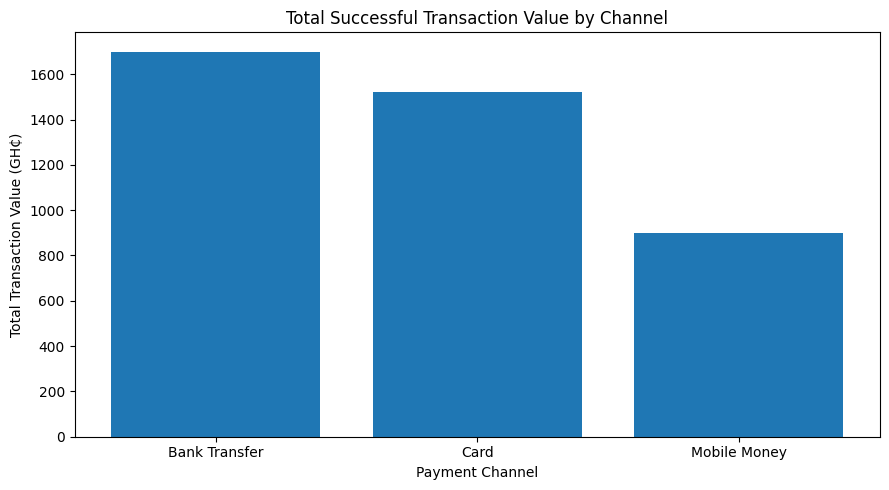

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    channel_summary['channel'],
    channel_summary['total_value']
)

plt.title('Total Successful Transaction Value by Channel')
plt.xlabel('Payment Channel')
plt.ylabel('Total Transaction Value (GH₵)')

plt.tight_layout()
plt.show()

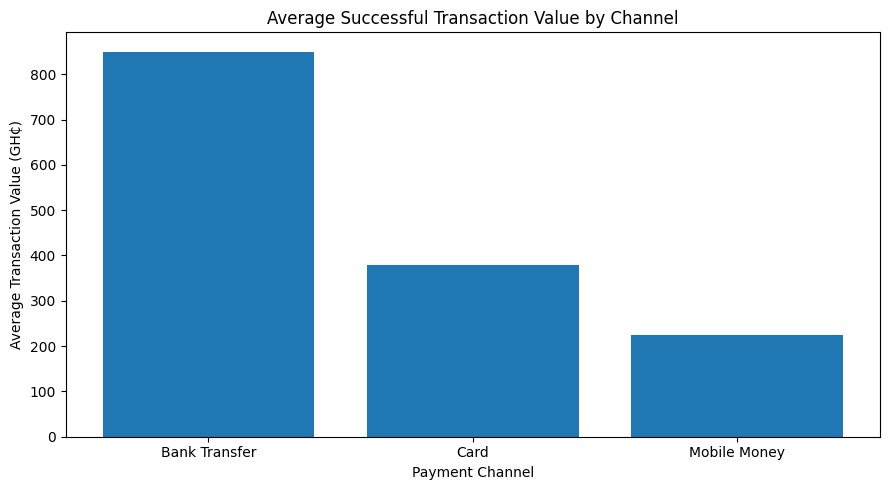

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    channel_summary['channel'],
    channel_summary['average_value']
)

plt.title('Average Successful Transaction Value by Channel')
plt.xlabel('Payment Channel')
plt.ylabel('Average Transaction Value (GH₵)')

plt.tight_layout()
plt.show()

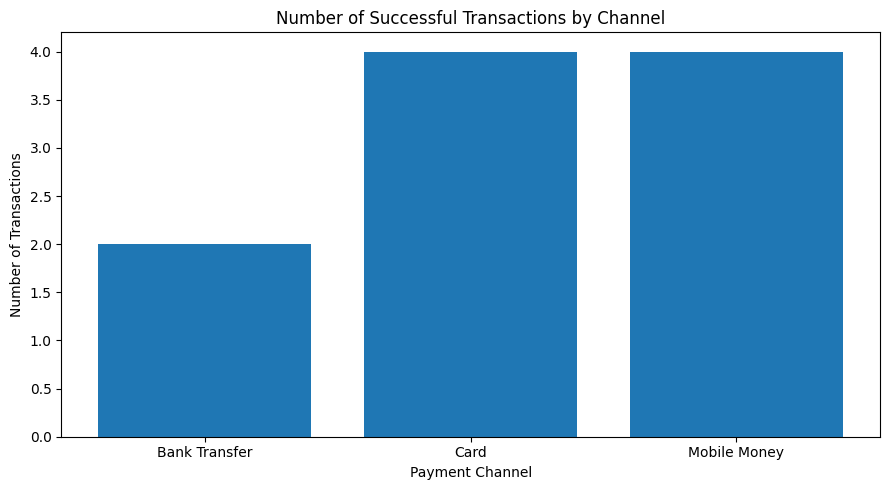

In [19]:
plt.figure(figsize=(9, 5))

plt.bar(
    channel_summary['channel'],
    channel_summary['transaction_count']
)

plt.title('Number of Successful Transactions by Channel')
plt.xlabel('Payment Channel')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

## Business Insights

1. Bank Transfer generated the highest total transaction value
   (GH₵1,700) from only two successful transactions. This suggests
   a higher average transaction value.

2. Card and Mobile Money recorded the highest transaction volumes,
   with four successful transactions each.

3. Card generated GH₵1,520, substantially more than Mobile Money's
   GH₵900, despite both channels recording the same number of
   successful transactions.

4. Mobile Money recorded the lowest average transaction value
   (GH₵225).

## Business Recommendations

- Investigate why Mobile Money transactions have a lower average
  value than Card transactions.
- Examine whether Bank Transfer attracts higher-value customers
  or larger purchases.
- Monitor both transaction volume and transaction value when
  evaluating payment channel performance.

## Analytical Limitation

This analysis uses a small synthetic dataset of 15 records after
duplicate removal. These findings demonstrate an analytical
approach and should not be treated as evidence of actual market
behaviour.